In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/citrnminhtin/predictstudentsdropoutandacademicsuccess/data.csv


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Import libraries successfully!")


Import libraries successfully!


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Duong dan dataset cua ban
data_path = "/kaggle/input/datasets/citrnminhtin/predictstudentsdropoutandacademicsuccess/data.csv"

df = pd.read_csv(data_path, sep=";")

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["Target"].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

display(df.head())


Dataset shape: (4424, 37)

Target distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Missing values: 0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [4]:

import os

# Kiem tra cac file da duoc them vao Kaggle
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith((".csv", ".json")):
            print(os.path.join(root, file))


/kaggle/input/datasets/citrnminhtin/predictstudentsdropoutandacademicsuccess/data.csv


In [6]:

# 36 dac trung dau vao
X = df.drop(columns=["Target"])

# Nhan can du doan
y = df["Target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClasses:", y.unique())
print("Missing values in X:", X.isnull().sum().sum())


X shape: (4424, 36)
y shape: (4424,)

Classes: ['Dropout' 'Graduate' 'Enrolled']
Missing values in X: 0


In [9]:

from pathlib import Path

required_files = [
    "train_indices.csv",
    "test_indices.csv",
    "train_folds.csv"
]

split_paths = {}

for name in required_files:
    matches = list(Path("/kaggle/input").rglob(name))
    split_paths[name] = matches

    if len(matches) == 1:
        print(f"FOUND: {name}")
        print(matches[0])
    elif len(matches) == 0:
        print(f"MISSING: {name}")
    else:
        print(f"MULTIPLE MATCHES: {name}")
        for path in matches:
            print(path)


FOUND: train_indices.csv
/kaggle/input/datasets/citrnminhtin/student-dropout-fixed-splits-v1/train_indices.csv
FOUND: test_indices.csv
/kaggle/input/datasets/citrnminhtin/student-dropout-fixed-splits-v1/test_indices.csv
FOUND: train_folds.csv
/kaggle/input/datasets/citrnminhtin/student-dropout-fixed-splits-v1/train_folds.csv


In [10]:

import pandas as pd
import numpy as np

# Duong dan bo chia du lieu
split_path = "/kaggle/input/datasets/citrnminhtin/student-dropout-fixed-splits-v1/"

# Doc 3 file
train_df = pd.read_csv(split_path + "train_indices.csv")
test_df = pd.read_csv(split_path + "test_indices.csv")
fold_df = pd.read_csv(split_path + "train_folds.csv")

# Kiem tra Train
print("=== TRAIN INDICES ===")
print("Shape:", train_df.shape)
print("Columns:", train_df.columns.tolist())
display(train_df.head())

# Kiem tra Test
print("\n=== TEST INDICES ===")
print("Shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
display(test_df.head())

# Kiem tra Cross-Validation
print("\n=== 5-FOLD CV ===")
print("Shape:", fold_df.shape)
print("Columns:", fold_df.columns.tolist())
display(fold_df.head())


=== TRAIN INDICES ===
Shape: (3539, 2)
Columns: ['train_position', 'row_id']


,train_position,row_id
0,0,2283
1,1,3874
2,2,2281
3,3,817
4,4,404



=== TEST INDICES ===
Shape: (885, 2)
Columns: ['test_position', 'row_id']


,test_position,row_id
0,0,1853
1,1,2399
2,2,510
3,3,242
4,4,3392



=== 5-FOLD CV ===
Shape: (3539, 3)
Columns: ['train_position', 'row_id', 'validation_fold']


,train_position,row_id,validation_fold
0,0,2283,5
1,1,3874,5
2,2,2281,2
3,3,817,1
4,4,404,5


In [11]:

from sklearn.ensemble import RandomForestClassifier

# Random Forest v1 - Basic
rf_v1 = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

print("Random Forest v1 initialized!")
print(rf_v1)


Random Forest v1 initialized!
RandomForestClassifier(n_jobs=-1, random_state=42)


In [13]:

# Sap xep theo vi tri Train co dinh
train_sorted = train_df.sort_values(
    "train_position"
).reset_index(drop=True)

fold_sorted = fold_df.sort_values(
    "train_position"
).reset_index(drop=True)

# Lay row_id tu bo chia cua nhom
train_idx = train_sorted["row_id"].to_numpy()
test_idx = test_df["row_id"].to_numpy()

# Kiem tra du lieu
assert len(train_idx) == 3539
assert len(test_idx) == 885
assert len(np.intersect1d(train_idx, test_idx)) == 0

assert np.array_equal(
    train_sorted["train_position"].to_numpy(),
    np.arange(3539)
)

assert np.array_equal(
    train_sorted["row_id"].to_numpy(),
    fold_sorted["row_id"].to_numpy()
)

# Tach X va y
X = df.drop(columns=["Target"])
y = df["Target"]

# RF v1 co ban: dung cac dac trung dang so goc
X = X.apply(pd.to_numeric, errors="raise")

X_train = X.iloc[train_idx].reset_index(drop=True)
y_train = y.iloc[train_idx].reset_index(drop=True)

# Lay Fold ID co dinh
fold_ids = fold_sorted["validation_fold"].to_numpy()

assert set(fold_ids) == {1, 2, 3, 4, 5}

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nSo mau trong tung fold:")
print(pd.Series(fold_ids).value_counts().sort_index())

print("\nData preparation successful!")


X_train: (3539, 36)
y_train: (3539,)

So mau trong tung fold:
1    708
2    708
3    708
4    708
5    707
Name: count, dtype: int64

Data preparation successful!


In [14]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report
)

# Luu ket qua tung fold
fold_results = []

# Luu du doan Out-of-Fold
oof_preds = np.full(len(y_train), "", dtype="<U16")

for fold in sorted(np.unique(fold_ids)):

    print(f"\n===== FOLD {fold} =====")

    train_mask = fold_ids != fold
    val_mask = fold_ids == fold

    X_tr = X_train.iloc[np.where(train_mask)[0]]
    X_val = X_train.iloc[np.where(val_mask)[0]]

    y_tr = y_train.iloc[np.where(train_mask)[0]]
    y_val = y_train.iloc[np.where(val_mask)[0]]

    # Tao model moi cho moi fold
    model = clone(rf_v1)

    # Huan luyen
    model.fit(X_tr, y_tr)

    # Du doan Validation
    y_pred = model.predict(X_val)
    oof_preds[val_mask] = y_pred

    # Danh gia
    accuracy = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(
        y_val, y_pred, average="macro"
    )
    precision = precision_score(
        y_val, y_pred,
        average="macro", zero_division=0
    )
    recall = recall_score(
        y_val, y_pred,
        average="macro", zero_division=0
    )

    fold_results.append({
        "Fold": fold,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Precision": precision,
        "Recall": recall
    })

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Macro-F1 : {macro_f1:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")

# Tong hop ket qua
results_df = pd.DataFrame(fold_results)

print("\n===== 5-FOLD CV RESULTS =====")
display(results_df)

print("\n===== CV MEAN +/- STD =====")

for metric in [
    "Accuracy", "Macro_F1",
    "Precision", "Recall"
]:
    mean = results_df[metric].mean()
    std = results_df[metric].std(ddof=0)
    print(f"{metric}: {mean:.4f} +/- {std:.4f}")



===== FOLD 1 =====
Accuracy : 0.7853
Macro-F1 : 0.7150
Precision: 0.7469
Recall   : 0.7020

===== FOLD 2 =====
Accuracy : 0.7613
Macro-F1 : 0.6650
Precision: 0.7073
Recall   : 0.6583

===== FOLD 3 =====
Accuracy : 0.7740
Macro-F1 : 0.6922
Precision: 0.7203
Recall   : 0.6834

===== FOLD 4 =====
Accuracy : 0.7500
Macro-F1 : 0.6506
Precision: 0.6858
Recall   : 0.6464

===== FOLD 5 =====
Accuracy : 0.7751
Macro-F1 : 0.7030
Precision: 0.7225
Recall   : 0.6934

===== 5-FOLD CV RESULTS =====


,Fold,Accuracy,Macro_F1,Precision,Recall
0,1,0.785311,0.715035,0.746869,0.701992
1,2,0.761299,0.664988,0.707309,0.658310
2,3,0.774011,0.692199,0.720344,0.683430
3,4,0.750000,0.650605,0.685762,0.646431
4,5,0.775106,0.703035,0.722499,0.693429



===== CV MEAN +/- STD =====
Accuracy: 0.7691 +/- 0.0122
Macro_F1: 0.6852 +/- 0.0239
Precision: 0.7166 +/- 0.0200
Recall: 0.6767 +/- 0.0211


In [15]:

labels = ["Dropout", "Enrolled", "Graduate"]

print("===== RANDOM FOREST V1 =====")
print("Classification Report (OOF):")

print(classification_report(
    y_train,
    oof_preds,
    labels=labels,
    zero_division=0
))

print("OOF Macro-F1:", round(
    f1_score(
        y_train, oof_preds,
        labels=labels,
        average="macro"
    ), 4
))


===== RANDOM FOREST V1 =====
Classification Report (OOF):
              precision    recall  f1-score   support

     Dropout       0.80      0.77      0.78      1137
    Enrolled       0.56      0.34      0.42       635
    Graduate       0.79      0.93      0.85      1767

    accuracy                           0.77      3539
   macro avg       0.72      0.68      0.69      3539
weighted avg       0.75      0.77      0.75      3539

OOF Macro-F1: 0.6859


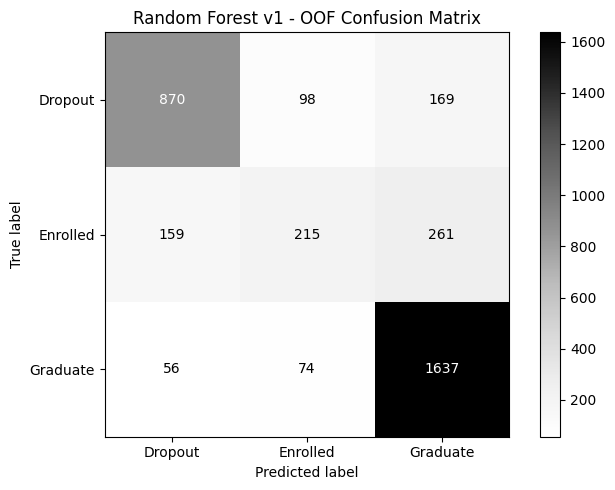

In [16]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    y_train,
    oof_preds,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    ax=ax,
    cmap="Greys",
    values_format="d"
)

plt.title("Random Forest v1 - OOF Confusion Matrix")
plt.tight_layout()
plt.show()


,Feature,Importance
30,Curricular units 2nd sem (approved),0.142283
31,Curricular units 2nd sem (grade),0.109008
24,Curricular units 1st sem (approved),0.091937
25,Curricular units 1st sem (grade),0.059588
12,Admission grade,0.043575
19,Age at enrollment,0.040287
16,Tuition fees up to date,0.038903
29,Curricular units 2nd sem (evaluations),0.038200
23,Curricular units 1st sem (evaluations),0.037504
6,Previous qualification (grade),0.037498


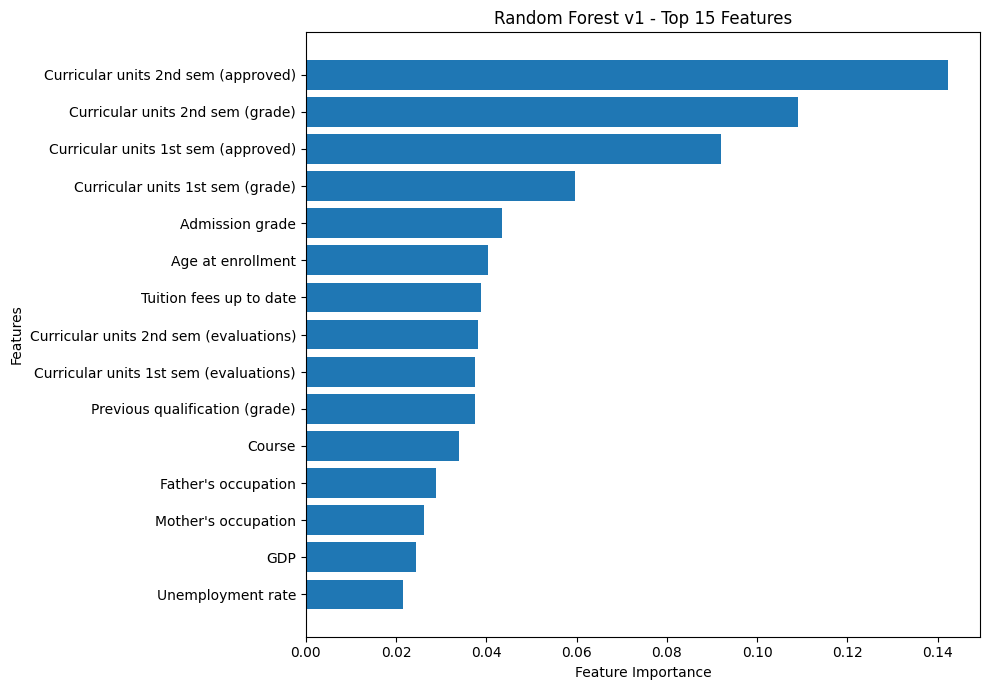

In [17]:

# Train RF v1 tren toan bo Train
# Khong su dung Test

rf_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_train, y_train)

# Lay muc do quan trong cua cac dac trung
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_final.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Hien thi 15 dac trung quan trong nhat
display(importance_df.head(15))

# Ve bieu do
top15 = importance_df.head(15)

plt.figure(figsize=(10, 7))
plt.barh(
    top15["Feature"][::-1],
    top15["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest v1 - Top 15 Features")
plt.tight_layout()
plt.show()


In [18]:

import os

output_dir = "/kaggle/working/RF_v1"
os.makedirs(output_dir, exist_ok=True)

# Luu ket qua 5 folds
results_df.to_csv(
    f"{output_dir}/fold_results.csv",
    index=False
)

# Luu Feature Importance
importance_df.to_csv(
    f"{output_dir}/feature_importance.csv",
    index=False
)

# Luu du doan OOF
oof_df = pd.DataFrame({
    "row_id": train_idx,
    "validation_fold": fold_ids,
    "y_true": y_train,
    "y_pred": oof_preds
})

oof_df.to_csv(
    f"{output_dir}/oof_predictions.csv",
    index=False
)

print("Saved RF v1 results successfully!")


Saved RF v1 results successfully!


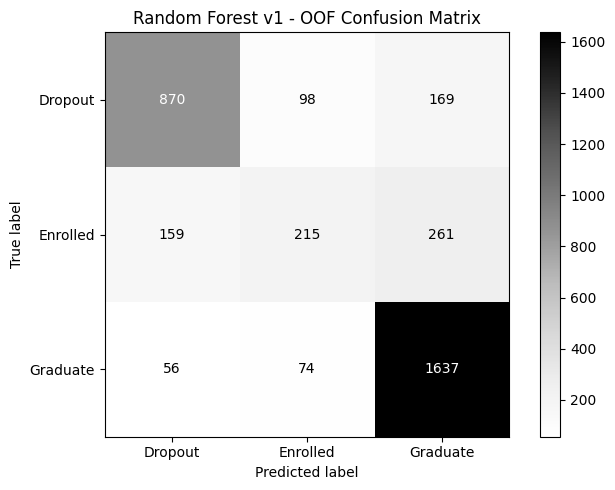

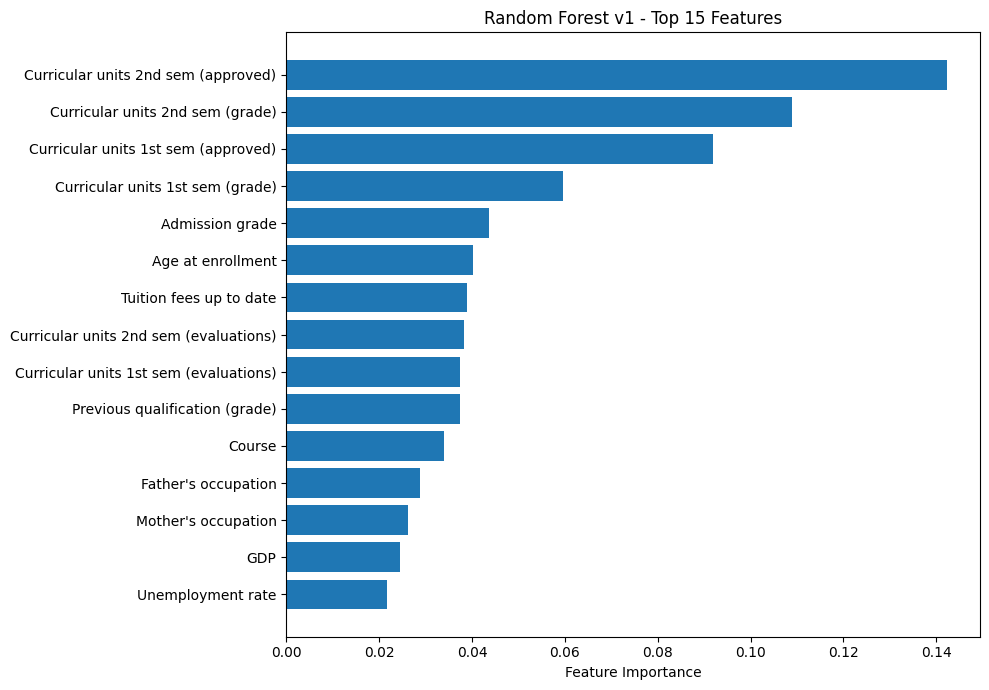

RF v1 artifacts saved successfully!
['feature_importance.png', 'oof_predictions.csv', 'confusion_matrix.png', 'feature_importance.csv', 'fold_results.csv', 'random_forest_v1.joblib']


In [19]:

import os
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

output_dir = "/kaggle/working/RF_v1"
os.makedirs(output_dir, exist_ok=True)

# 1. Luu Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)
disp.plot(ax=ax, cmap="Greys", values_format="d")

plt.title("Random Forest v1 - OOF Confusion Matrix")
plt.tight_layout()
plt.savefig(
    f"{output_dir}/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 2. Luu Feature Importance
top15 = importance_df.head(15).iloc[::-1]

plt.figure(figsize=(10, 7))
plt.barh(top15["Feature"], top15["Importance"])
plt.title("Random Forest v1 - Top 15 Features")
plt.xlabel("Feature Importance")
plt.tight_layout()

plt.savefig(
    f"{output_dir}/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 3. Luu model da fit tren toan bo Train
joblib.dump(
    rf_final,
    f"{output_dir}/random_forest_v1.joblib"
)

print("RF v1 artifacts saved successfully!")
print(os.listdir(output_dir))


In [21]:

from pathlib import Path

output_dir = Path("/kaggle/working/RF_v1")

print("=== RANDOM FOREST V1 ===")

print("\n5-Fold CV Results:")
display(results_df)

print("\nCV Mean +/- Std:")
for metric in ["Accuracy", "Macro_F1", "Precision", "Recall"]:
    print(
        f"{metric}: "
        f"{results_df[metric].mean():.4f} +/- "
        f"{results_df[metric].std(ddof=0):.4f}"
    )

print("\nSaved files:")
for file in sorted(output_dir.iterdir()):
    print(file.name)

print("\nRF v1 summary completed!")


=== RANDOM FOREST V1 ===

5-Fold CV Results:


,Fold,Accuracy,Macro_F1,Precision,Recall
0,1,0.785311,0.715035,0.746869,0.701992
1,2,0.761299,0.664988,0.707309,0.658310
2,3,0.774011,0.692199,0.720344,0.683430
3,4,0.750000,0.650605,0.685762,0.646431
4,5,0.775106,0.703035,0.722499,0.693429



CV Mean +/- Std:
Accuracy: 0.7691 +/- 0.0122
Macro_F1: 0.6852 +/- 0.0239
Precision: 0.7166 +/- 0.0200
Recall: 0.6767 +/- 0.0211

Saved files:
confusion_matrix.png
feature_importance.csv
feature_importance.png
fold_results.csv
oof_predictions.csv
random_forest_v1.joblib

RF v1 summary completed!
